In [58]:
## DAY 3 - Practical Task
## Anugraheetha Bin Saj
## 05/11/2026

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score, roc_curve, confusion_matrix
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# same colour for each model in every chart
COLORS = {
    "Decision Tree": "#2a78d6",
    "Random Forest": "#eb6834",
    "Gradient Boosting": "#1baf7a",
    "Random Forest (tuned)": "#6250d6",
}
INK, INK_SOFT, GRID = "#0b0b0b", "#52514e", "#e4e3df"
blue_ramp = LinearSegmentedColormap.from_list("blue", ["#fcfcfb", "#2a78d6"])

1.Load breast cancer classification dataset from scikit-learn

Samples: 569
Features: 30
Class counts: {'malignant': 212, 'benign': 357}


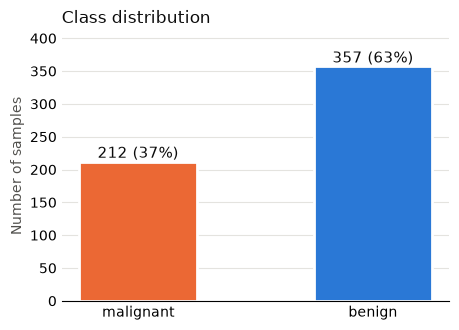

In [50]:
data = load_breast_cancer()
X, y = data.data, data.target
class_names = data.target_names  # ['malignant', 'benign']

print("Samples:", X.shape[0])
print("Features:", X.shape[1])
print("Class counts:", {str(n): int(c) for n, c in zip(class_names, np.bincount(y))})
counts = np.bincount(y)
fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(class_names, counts, color=["#eb6834", "#2a78d6"], width=0.5,
              edgecolor="white", linewidth=2)
for bar, c in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, c + 6, f"{c} ({c / counts.sum():.0%})",
            ha="center", fontsize=11, color=INK)
ax.set_title("Class distribution", loc="left", color=INK)
ax.set_ylabel("Number of samples", color=INK_SOFT)
ax.set_ylim(0, counts.max() * 1.15)
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
plt.show()

The dataset has 569 samples and 30 numeric features.About 357 (63%) are benign and 212 (37%) are malignant, so the classes are neither perfectly balanced nor badly skewed.A model that always predicted “benign” would already be right about 63% of the time, which is why accuracy alone is not enough.

2.Train a Decision Tree, Random Forest and Gradient Boosting model (use the same split and metric for a fair comaprison)

In [51]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    acc = accuracy_score(y_test, model.predict(X_test))
    print(f"{name}: accuracy = {acc:.3f}")

Decision Tree: accuracy = 0.912
Random Forest: accuracy = 0.956
Gradient Boosting: accuracy = 0.956


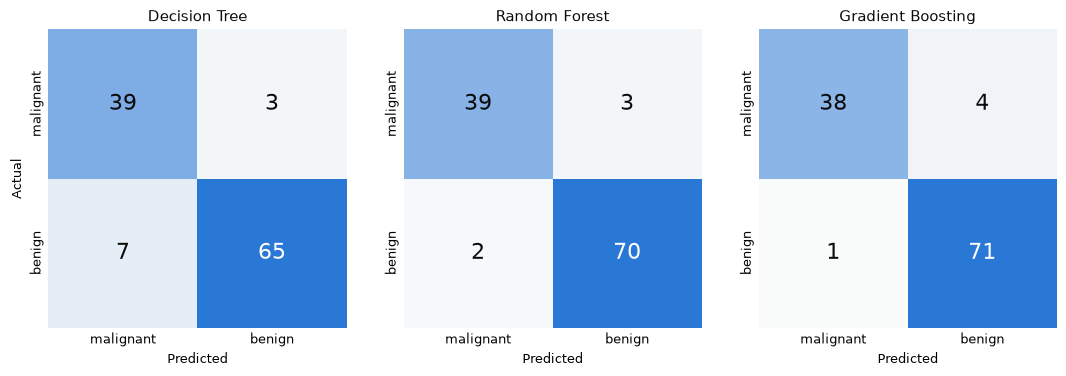

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test))
    ax.imshow(cm, cmap=blue_ramp, vmin=0, vmax=cm.max())
    for r in range(2):
        for c in range(2):
            ax.text(c, r, cm[r, c], ha="center", va="center", fontsize=16,
                    color="white" if cm[r, c] > cm.max() * 0.8 else INK)
    ax.set_xticks([0, 1], class_names, fontsize=9)
    ax.set_yticks([0, 1], class_names, fontsize=9, rotation=90, va="center")
    ax.set_xlabel("Predicted", fontsize=9)
    ax.set_title(name, fontsize=11, color=INK)
    ax.tick_params(length=0)
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel("Actual", fontsize=9)
plt.tight_layout()
plt.show()

Random Forest and Gradient Boosting both reach 0.956 accuracy on the test set, while the single Decision Tree is lower at 0.912. The confusion matrices show the ensembles don’t make the same mistakes: Random Forest misses 3 malignant tumours and raises 2 false alarms, while Gradient Boosting misses 4 malignant tumours and raises only 1 false alarm. The Decision Tree is the weakest on benign cases, wrongly flagging 7 of them as malignant. Missing a malignant case is the more serious error in a medical setting, so equal accuracy does not mean equal usefulness.

3.Tune Random Forest hyperparameters and report the best combination

In [53]:
# grid search with 5-fold CV on the training data only,
# so the test set stays untouched until the final comparison
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "max_features": ["sqrt", "log2"],
}

search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Best parameters:")
for param, value in search.best_params_.items():
    print(f"  {param}: {value}")
print(f"Best cross-validated ROC-AUC: {search.best_score_:.4f}")
print(f"Combinations tried: {len(search.cv_results_['params'])}")

models["Random Forest (tuned)"] = search.best_estimator_

Best parameters:
  max_depth: None
  max_features: log2
  min_samples_split: 2
  n_estimators: 100
Best cross-validated ROC-AUC: 0.9907
Combinations tried: 36


n_estimators     100     200     300
max_depth                           
5             0.9898  0.9906  0.9902
10            0.9907  0.9905  0.9900
None          0.9907  0.9906  0.9900


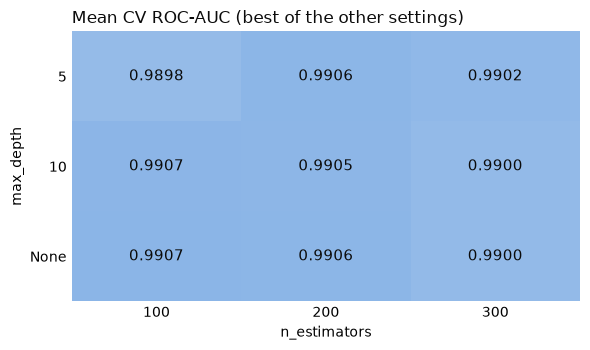

In [54]:
results = pd.DataFrame(search.cv_results_)
results["max_depth"] = [str(p["max_depth"]) for p in search.cv_results_["params"]]
results["n_estimators"] = [p["n_estimators"] for p in search.cv_results_["params"]]
pivot = (results.groupby(["max_depth", "n_estimators"])["mean_test_score"]
         .max().unstack())
pivot = pivot.loc[["5", "10", "None"]]
print(pivot.round(4))

# fixed colour scale so tiny differences are not blown up into big colour changes
lo, hi = 0.98, 1.0
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.imshow(pivot.values, cmap=blue_ramp, vmin=lo, vmax=hi, aspect="auto")
for r in range(pivot.shape[0]):
    for c in range(pivot.shape[1]):
        v = pivot.values[r, c]
        ax.text(c, r, f"{v:.4f}", ha="center", va="center", fontsize=11,
                color="white" if v > lo + (hi - lo) * 0.8 else INK)
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.set_xlabel("n_estimators")
ax.set_ylabel("max_depth")
ax.set_title("Mean CV ROC-AUC (best of the other settings)", loc="left", color=INK)
ax.tick_params(length=0)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.tight_layout()
plt.show()

The grid search tried 36 combinations and the best was max_depth=None, max_features='log2', min_samples_split=2 and n_estimators=100, with a cross-validated ROC-AUC of 0.9907. What stands out is how little the settings matter on this dataset. Every n_estimators / max_depth pair lands between 0.9898 and 0.9907, a spread under 0.001, which is smaller than normal fold-to-fold variation. Using 300 trees instead of 100 gave no gain, and limiting depth to 5 cost almost nothing. The winning combination is basically the default forest with a different max_features, so tuning here confirms the default was already a good choice instead of finding a big improvement.

4.Compare ROC-AUC,F1 or another task-appropriate metric for all models

In [55]:
rows = []
roc_data = {}
for name, model in models.items():
    predictions = model.predict(X_test)
    scores = model.predict_proba(X_test)[:, 1]   # probability of benign
    fpr, tpr, _ = roc_curve(y_test, scores)
    roc_data[name] = (fpr, tpr)
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, scores),
    })

comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison

,Accuracy,F1,ROC-AUC
Model,,,
Decision Tree,0.912,0.929,0.916
Random Forest,0.956,0.966,0.994
Gradient Boosting,0.956,0.966,0.991
Random Forest (tuned),0.956,0.966,0.992


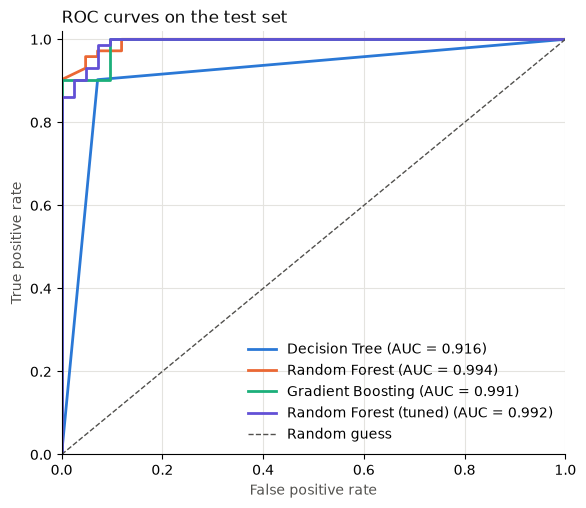

In [56]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, (fpr, tpr) in roc_data.items():
    ax.plot(fpr, tpr, color=COLORS[name], linewidth=2,
            label=f"{name} (AUC = {comparison.loc[name, 'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=INK_SOFT, linestyle="--", linewidth=1, label="Random guess")
ax.set_xlabel("False positive rate", color=INK_SOFT)
ax.set_ylabel("True positive rate", color=INK_SOFT)
ax.set_title("ROC curves on the test set", loc="left", color=INK)
ax.grid(True, color=GRID)
ax.set_axisbelow(True)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", frameon=False)
plt.show()

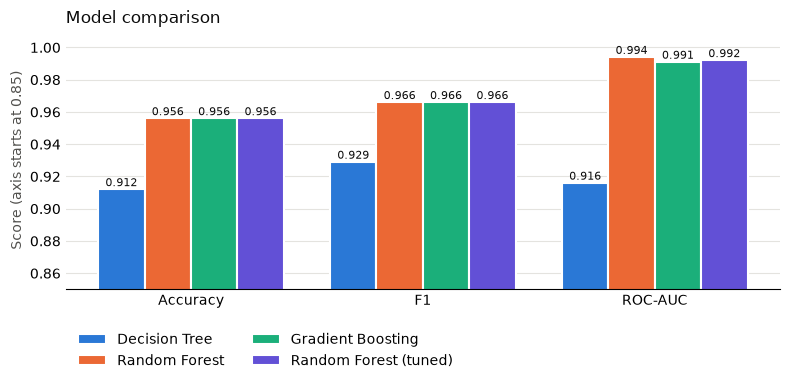

In [57]:
metrics = ["Accuracy", "F1", "ROC-AUC"]
names = list(comparison.index)
width = 0.2
x = np.arange(len(metrics))

fig, ax = plt.subplots(figsize=(8, 4))
for i, name in enumerate(names):
    vals = comparison.loc[name, metrics].values
    bars = ax.bar(x + (i - 1.5) * width, vals, width, color=COLORS[name],
                  edgecolor="white", linewidth=1.5, label=name)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 0.002, f"{v:.3f}",
                ha="center", fontsize=8, color=INK)
ax.set_xticks(x, metrics)
ax.set_ylim(0.85, 1.01)
ax.set_ylabel("Score (axis starts at 0.85)", color=INK_SOFT)
ax.set_title("Model comparison", loc="left", color=INK)
ax.yaxis.grid(True, color=GRID)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.legend(frameon=False, ncol=2, loc="upper left", bbox_to_anchor=(0, -0.12))
plt.tight_layout()
plt.show()

The ensembles are clearly better than the single tree. The Decision Tree gets 0.912 accuracy, 0.929 F1 and 0.916 ROC-AUC. Random Forest, Gradient Boosting and the tuned Random Forest all get 0.956 accuracy and 0.966 F1, with ROC-AUC between 0.991 and 0.994. In practice that's 5 wrong predictions out of 114 for the ensembles and 10 for the tree. The ROC plot shows the same thing: the tree's curve is just a few straight lines (one tree can only give a few different probabilities), while the ensemble curves stay near the top-left corner.

I can't really pick a winner between the three ensembles. They differ by one or two test samples, and the tuned forest (0.992) actually scored a little lower than the default one (0.994). With only 114 test samples that gap doesn't mean much. F1 and ROC-AUC agree with accuracy on the ranking, which is reassuring given the 63/37 class split. A more reliable comparison would need cross-validation instead of a single split.